In [4]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns
from pandas.plotting import scatter_matrix

In [2]:
# load data into df

df = pd.read_csv("../data/processed/pharma_sales_data_string_cleaned.csv", encoding="utf-8", na_values=["", "NA", "-", "?"])

# Numeric vs Numeric

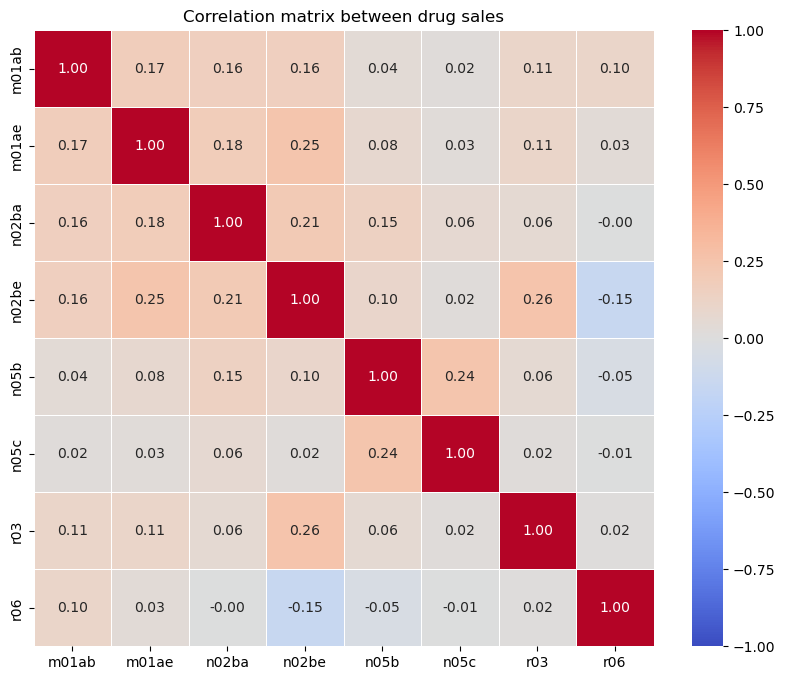

In [3]:
# get numeric columns
numeric_columns = [c for c in df.columns if(df[c].dtype == "float64")]

# compute correlation matrix
corr_matrix = df[numeric_columns].corr(method="spearman")

# plot the correlation heatmap
plt.figure(figsize=(10,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.5,
    )
plt.title("Correlation matrix between drug sales")
plt.show()

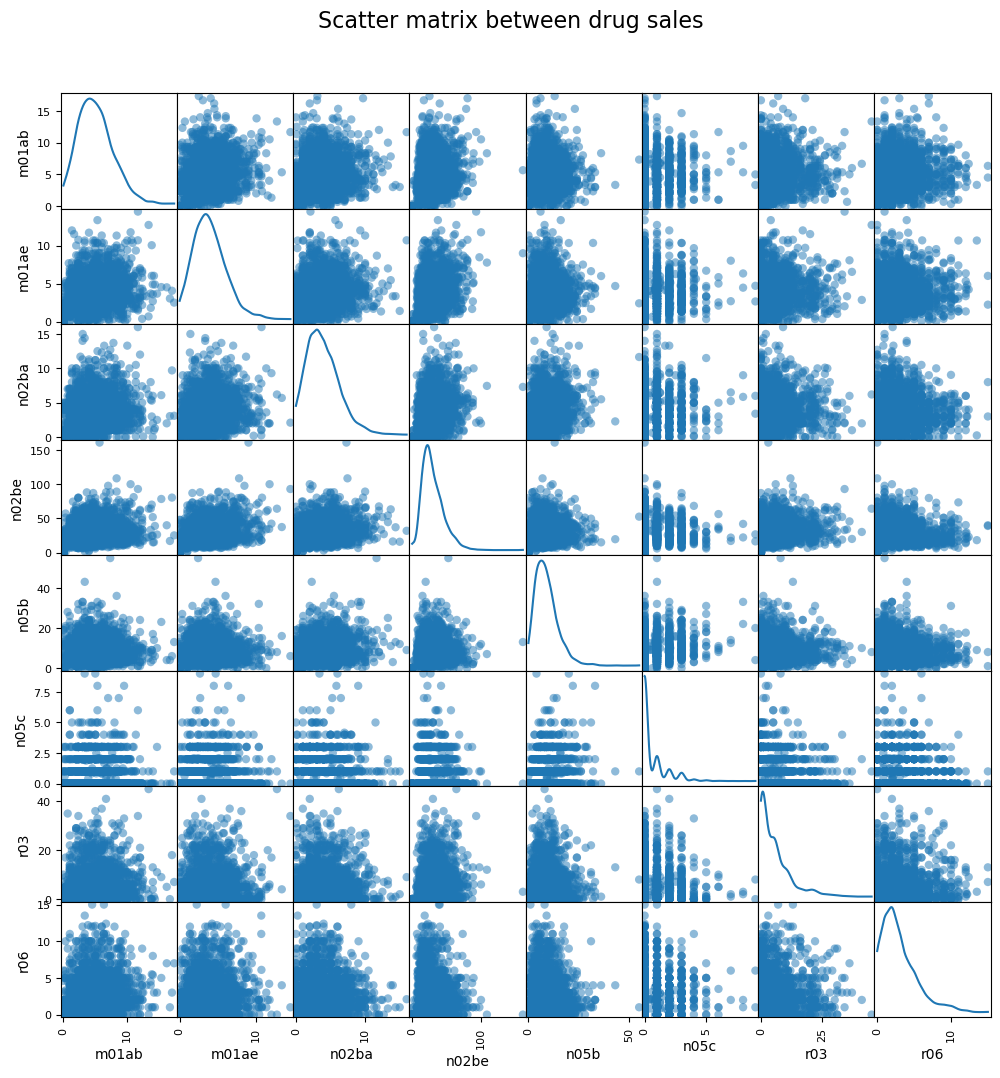

In [6]:
# plot scatter matrix using pandas

scatter_matrix(
    df[numeric_columns],
    figsize=(12,12),
    alpha=0.5,
    diagonal="kde",
    marker="o"
)
plt.suptitle("Scatter matrix between drug sales", y=0.95, fontsize=16)
plt.show()

# Numeric vs Categorical

In [7]:
df.columns

Index(['datum', 'm01ab', 'm01ae', 'n02ba', 'n02be', 'n05b', 'n05c', 'r03',
       'r06', 'year', 'month', 'hour', 'weekday_name', 'datum_parsed'],
      dtype='object')

In [10]:
stats = (
    df.groupby("weekday_name")[numeric_columns]
    .agg(["count", "mean", "median"])
    .stack(level=0) # <--- variables become rows
    .rename_axis(["weekday_name", "drug_type"])
    .round(2)
)
stats

count   mean  median
weekday_name drug_type                      
friday       m01ab        301   4.77    4.50
             m01ae        301   3.71    3.46
             n02ba        301   3.88    3.65
             n02be        301  28.59   26.00
             n05b         301   9.90    9.00
             n05c         301   0.76    0.00
             r03          301   5.83    3.00
             r06          301   2.80    2.00
monday       m01ab        301   5.06    5.00
             m01ae        301   3.72    3.66
             n02ba        301   3.89    3.60
             n02be        301  29.23   26.20
             n05b         301   9.25    9.00
             n05c         301   0.62    0.00
             r03          301   5.95    4.00
             r06          301   2.90    2.00
saturday     m01ab        301   5.73    5.01
             m01ae        301   4.36    3.99
             n02ba        301   4.19    4.00
             n02be        301  33.58   31.30
             n05b         301   8.57    8.00
             n05c         301   0.55    0.00
             r03          301   5.41    4.00
             r06          301   3.28    3.00
sunday       m01ab        301   5.29    5.00
             m01ae        301   4.60    4.34
             n02ba        301   3.51    3.00
             n02be        301  33.39   29.00
             n05b         301   5.80    5.00
             n05c         301   0.33    0.00
             r03          301   5.22    4.00
             r06          301   2.99    2.00
thursday     m01ab        301   4.55    4.33
             m01ae        301   3.63    3.46
             n02ba        301   3.69    3.20
             n02be        301  28.17   25.60
             n05b         301   8.72    8.00
             n05c         301   0.51    0.00
             r03          301   5.30    3.00
             r06          301   2.62    2.00
tuesday      m01ab        301   5.05    4.68
             m01ae        301   3.55    3.34
             n02ba        301   4.23    4.00
             n02be        301  28.37   26.20
             n05b         301   9.62    9.00
             n05c         301   0.73    0.00
             r03          301   5.41    4.00
             r06          301   3.05    3.00
wednesday    m01ab        300   4.80    4.34
             m01ae        300   3.70    3.36
             n02ba        300   3.77    3.30
             n02be        300  28.07   26.10
             n05b         300  10.12    9.00
             n05c         300   0.65    0.00
             r03          300   5.45    3.50
             r06          300   2.67    2.00

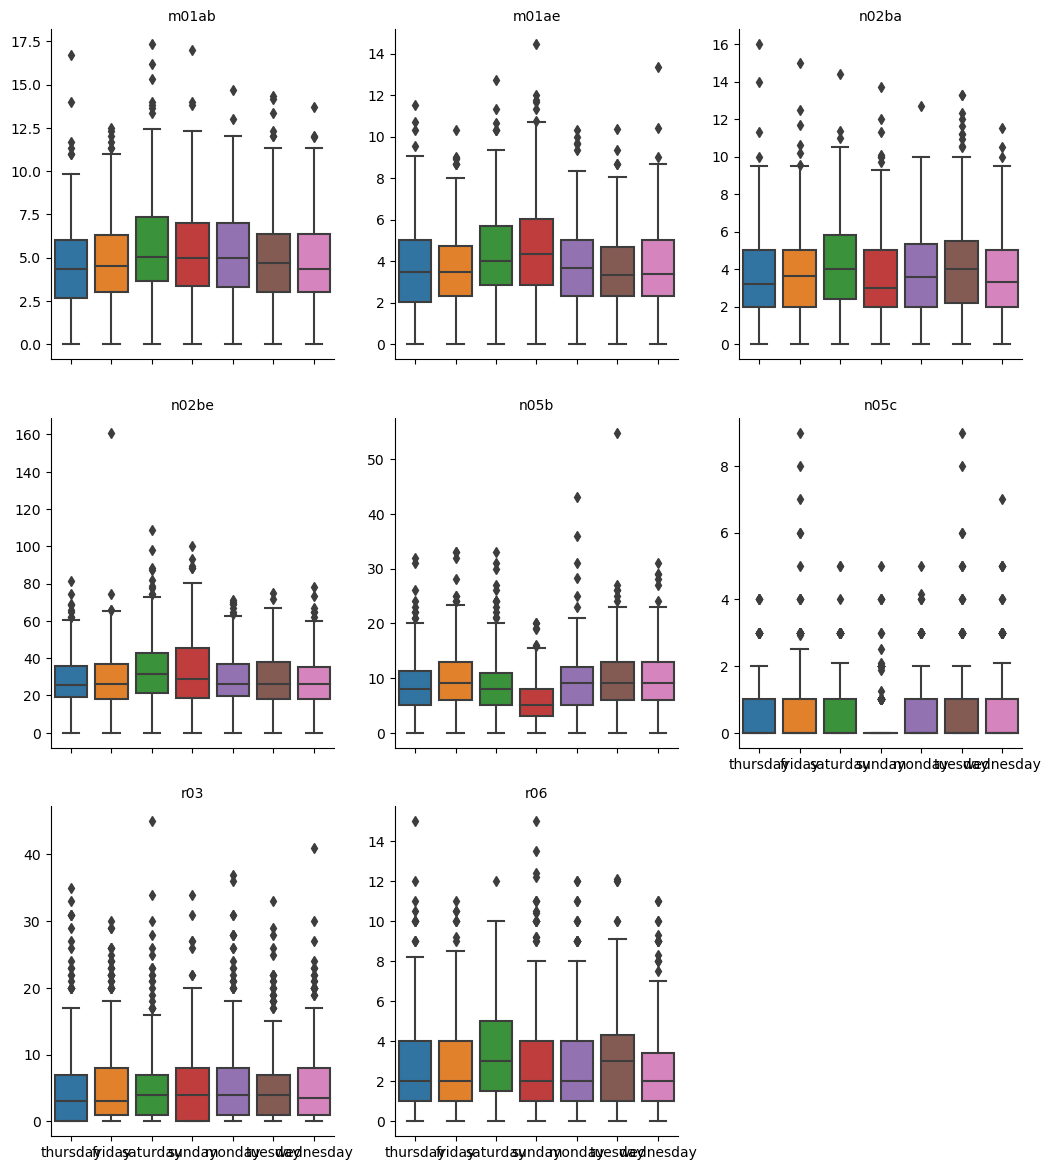

In [11]:
# catplot

long = df.melt(id_vars="weekday_name", value_vars=numeric_columns,
               var_name="drug_type", value_name="value")

g = sns.catplot(
    data=long, x="weekday_name", y="value",
    col="drug_type", kind="box",
    sharey=False,
    col_wrap=3, height=4, aspect=0.9,
)

g.set_titles("{col_name}")
g.set_axis_labels("", "")
plt.show()